# Phase 3 · NB08 · TREAD-TWO / ATLAS

**One new classifier fit · existing data · full direct CSV evidence · completed-update recovery.**

The declared TREAD-ONE seed-3/epoch-20 dense anchor stays frozen. A custom local
encoder compares 32 atlas patches with 18 literal training-source reference cases.
There are **81,274 new trainable parameters** and 1,453,433 total parameters.
No workstation is changed. Mileage classes remain proxies, not depth/safety labels.

Before Run All:

1. Select **GPU T4 ×2** and enable **Internet**.
2. Attach the **expanded** `shanmuk4622/tire-dataset-prepared-phase2` input directly
   from Kaggle. Do not download/copy another dataset or attach a ZIP-only version.
3. Enable Kaggle Secret **HF_TOKEN**, with write access to
   `Shanmuk4622/tyre-wear-study`. No alternative credential source is used.
4. Start with at least **12 GiB free**. The output guard is 16 GB within the
   user's 20 GB output budget; actual mounts/free space are measured. Larger
   scratch is not assumed. Scientific tables are not dropped to fit storage.
5. Choose **Run All**. The live recovery/space gate must pass before the measured
   cell starts. Keep this executed notebook for the completion audit.

**GPU ownership:** GPU 0 trains the one candidate; GPU 1 evaluates an immutable
model copy at barriers. This is not DDP or two independent measured fits.
FP32 is deliberate; no Torch upgrade or AMP compatibility repair is needed.

**30 October repair:** the model/runtime/bank/recipe and run namespace are
unchanged. An audited external launcher corrects the accidental hourly HTTP
request cap: API/resolver requests use five-minute windows, commit attempts
keep a separate hourly guard, and server delay headers remain authoritative.
Already completed recovery gates are reused; native/CSV progress is preserved.


In [1]:
import base64, hashlib, importlib.metadata, json, os, subprocess, sys
from pathlib import Path
assert Path('/kaggle/working').exists(), 'Run this notebook on Kaggle.'
WORK = Path('/kaggle/working/tread_two_atlas')
SOURCE = WORK / 'source'
WORK.mkdir(parents=True, exist_ok=True)
SOURCE.mkdir(exist_ok=True)
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
try:
    hub_version = importlib.metadata.version('huggingface_hub')
except importlib.metadata.PackageNotFoundError:
    hub_version = None
if hub_version != '0.36.2':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', 'huggingface_hub==0.36.2'])
payload = json.loads(base64.b64decode('...'))
for name, value in payload.items():
    target = (SOURCE / name).resolve()
    assert target.is_relative_to(SOURCE.resolve()) and '..' not in Path(name).parts
    body = base64.b64decode(value)
    if target.exists():
        assert target.read_bytes() == body, 'Existing source differs. Preserve the run and request a compatibility review.'
    else:
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(body)
catalog = json.loads((SOURCE / 'FILES.json').read_text())
assert all(hashlib.sha256((SOURCE/name).read_bytes()).hexdigest() == item['sha256'] for name,item in catalog.items())
print('Exact isolated source and reference bank ready:', len(catalog), 'files. No model has been fitted by this cell.')
REPAIR_PAYLOAD = 'IiIiQXVkaXRlZCBOQjA4IHRyYW5zcG9ydCByZXBhaXI7IGZyb3plbiBtb2RlbC9ydW50aW1lIGZpbGVzIGFyZSBuZXZlciBlZGl0ZWQuCgpBUEkvcmVzb2x2ZXIgSFRUUCByZXF1ZXN0cyB1c2UgZml2ZS1taW51dGUgd2luZG93cy4gQ29tbWl0IGF0dGVtcHRzIGtlZXAgYQpzZXBhcmF0ZSBjb25zZXJ2YXRpdmUgaG91cmx5IGJ1ZGdldC4gU2VydmVyIHJlc2V0L1JldHJ5LUFmdGVyIGFsd2F5cyB3aW5zLgpUaGlzIGxhdW5jaGVyIGlzIHB1Ymxpc2hlZCBhbG9uZ3NpZGUgc25hcHNob3RzIGFzIGV4cGxpY2l0IHJlcGFpciBwcm92ZW5hbmNlLgoiIiIKaW1wb3J0IGFyZ3BhcnNlCmltcG9ydCBoYXNobGliCmltcG9ydCBqc29uCmltcG9ydCBtYXRoCmltcG9ydCByZQppbXBvcnQgc2h1dGlsCmltcG9ydCBzeXMKaW1wb3J0IHRpbWUKaW1wb3J0IHRyYWNlYmFjawpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKZnJvbSB1cmxsaWIucGFyc2UgaW1wb3J0IHVybHBhcnNlCgpSRVZJU0lPTiA9ICduYjA4LXRyYW5zcG9ydC0yMDI2MTAzMC1yMScKUE9MSUNZID0geydhcGknOiAoMzAwLCA5NiksICdyZXNvbHZlcic6ICgzMDAsIDQwMCksICd0cmFuc2Zlcic6ICgzMDAsIDEwMDApLCAncmVwb19jb21taXQnOiAoMzYwMCwgOTYpfQpfSU5TVEFMTEVEID0gTm9uZQoKCmRlZiBpbnN0YWxsKHNvdXJjZSwgd29yaywgaW52ZW50b3J5X3NoYT1Ob25lLCBjbG9jaz1Ob25lLCBzbGVlcGVyPU5vbmUpOgogICAgZ2xvYmFsIF9JTlNUQUxMRUQKICAgIHNvdXJjZSwgd29yayA9IFBhdGgoc291cmNlKS5yZXNvbHZlKCksIFBhdGgod29yaykucmVzb2x2ZSgpCiAgICBpbnZlbnRvcnlfYm9keSA9IChzb3VyY2UgLyAnRklMRVMuanNvbicpLnJlYWRfYnl0ZXMoKQogICAgaW52ZW50b3J5X2RpZ2VzdCA9IGhhc2hsaWIuc2hhMjU2KGludmVudG9yeV9ib2R5KS5oZXhkaWdlc3QoKQogICAgaWYgaW52ZW50b3J5X3NoYToKICAgICAgICBhc3NlcnQgaW52ZW50b3J5X2RpZ2VzdCA9PSBpbnZlbnRvcnlfc2hhLCAnUmVwYWlyIHJlZnVzZXMgYSBkaWZmZXJlbnQgZnJvemVuIHNvdXJjZSBpbnZlbnRvcnknCiAgICBpbnZlbnRvcnkgPSBqc29uLmxvYWRzKGludmVudG9yeV9ib2R5KQogICAgYXNzZXJ0IGxlbihpbnZlbnRvcnkpID09IDI0LCAnVGhpcyByZXBhaXIgaXMgZm9yIHRoZSBvcmlnaW5hbCBOQjA4IHNvdXJjZSBvbmx5JwogICAgZm9yIG5hbWUsIGl0ZW0gaW4gaW52ZW50b3J5Lml0ZW1zKCk6CiAgICAgICAgdGFyZ2V0ID0gKHNvdXJjZSAvIG5hbWUpLnJlc29sdmUoKQogICAgICAgIGFzc2VydCB0YXJnZXQuaXNfcmVsYXRpdmVfdG8oc291cmNlKQogICAgICAgIGJvZHkgPSB0YXJnZXQucmVhZF9ieXRlcygpCiAgICAgICAgYXNzZXJ0IGxlbihib2R5KSA9PSBpdGVtWydieXRlcyddIGFuZCBoYXNobGliLnNoYTI1Nihib2R5KS5oZXhkaWdlc3QoKSA9PSBpdGVtWydzaGEyNTYnXSwgJ0Zyb3plbiBzb3VyY2UgY2hhbmdlZDogJyArIG5hbWUKICAgIGlmIF9JTlNUQUxMRUQ6CiAgICAgICAgYXNzZXJ0IF9JTlNUQUxMRURbJ3NvdXJjZSddID09IHNvdXJjZSBhbmQgX0lOU1RBTExFRFsnd29yayddID09IHdvcmsKICAgICAgICByZXR1cm4gX0lOU1RBTExFRAogICAgc3lzLnBhdGguaW5zZXJ0KDAsIHN0cihzb3VyY2UpKQogICAgZnJvbSBjb21tb24gaW1wb3J0IGF0b21pYywgZGlnZXN0LCBldmVudCwgZmlsZV9tZXRhLCByZWFkLCBzaGEKICAgIGltcG9ydCByYXRlX2J1ZGdldAogICAgaW1wb3J0IHN0b3JlCiAgICByZXBhaXIgPSB3b3JrIC8gJ05CMDhfVFJBTlNQT1JUX1JFUEFJUicKICAgIHJlcGFpci5ta2RpcihwYXJlbnRzPVRydWUsIGV4aXN0X29rPVRydWUpCiAgICBub3cgPSBjbG9jayBvciB0aW1lLnRpbWUKICAgIHBhdXNlID0gc2xlZXBlciBvciB0aW1lLnNsZWVwCiAgICBsb2cgPSByZXBhaXIgLyAnRVZFTlRTLmpzb25sJwogICAgb3duX3NvdXJjZSA9IFBhdGgoX19maWxlX18pLnJlc29sdmUoKQogICAgbWV0YWRhdGEgPSBkaWN0KHJldmlzaW9uPVJFVklTSU9OLCBzb3VyY2VfaW52ZW50b3J5X3NoYTI1Nj1pbnZlbnRvcnlfZGlnZXN0LAogICAgICAgICAgICAgICAgICAgIGxhdW5jaGVyX3NoYTI1Nj1zaGEob3duX3NvdXJjZSksIGZyb3plbl9zb3VyY2VfZmlsZXM9MjQsCiAgICAgICAgICAgICAgICAgICAgcG9saWN5PXtuYW1lOmRpY3Qod2luZG93X3NlY29uZHM9d2luZG93LCBsb2NhbF9saW1pdD1saW1pdCkgZm9yIG5hbWUsKHdpbmRvdyxsaW1pdCkgaW4gUE9MSUNZLml0ZW1zKCl9LAogICAgICAgICAgICAgICAgICAgIHNlcnZlcl9oZWFkZXJzX2F1dGhvcml0YXRpdmU9VHJ1ZSwgbW9kZWxfb3JfcmVjaXBlX2NoYW5nZWQ9RmFsc2UsCiAgICAgICAgICAgICAgICAgICAgc291cmNlX0ZJTEVTX2NoYW5nZWQ9RmFsc2UsIGNvbnRyYWN0X29yX25hbWVzcGFjZV9jaGFuZ2VkPUZhbHNlLAogICAgICAgICAgICAgICAgICAgIHJhdGlvbmFsZT0nUmVwbGFjZSBlcnJvbmVvdXMgOTYtSFRUUC1yZXF1ZXN0cy9ob3VyIGNhcCB3aXRoIGJ1Y2tldC1zcGVjaWZpYyBIVFRQIHdpbmRvd3M7IHJldGFpbiBob3VybHkgY29tbWl0LWF0dGVtcHQgZ3VhcmQuJykKICAgIGF0b21pYyhyZXBhaXIgLyAnUkVQQUlSLmpzb24nLCBtZXRhZGF0YSkKICAgIGlmICh3b3JrIC8gJ0hGX0hUVFBfQlVER0VULmpzb24nKS5leGlzdHMoKSBhbmQgbm90IChyZXBhaXIgLyAnSFRUUF9CVURHRVRfQkVGT1JFLmpzb24nKS5leGlzdHMoKToKICAgICAgICBzaHV0aWwuY29weTIod29yayAvICdIRl9IVFRQX0JVREdFVC5qc29uJywgcmVwYWlyIC8gJ0hUVFBfQlVER0VUX0JFRk9SRS5qc29uJykKICAgIGV2ZW50KGxvZywgJ3JlcGFpcl9pbnN0YWxsZWQnLCByZXZpc2lvbj1SRVZJU0lPTiwgaW52ZW50b3J5X3NoYTI1Nj1pbnZlbnRvcnlfZGlnZXN0LCBwcm9jZXNzPXN5cy5hcmd2WzBdKQoKICAgIGRlZiByZXNlcnZlKHNlbGYsIGJ1Y2tldCk6CiAgICAgICAgYXNzZXJ0IGJ1Y2tldCBpbiBQT0xJQ1kKICAgICAgICBkZWZhdWx0X3dpbmRvdywgZGVmYXVsdF9saW1pdCA9IFBPTElDWVtidWNrZXRdCiAgICAgICAgbmV4dF9ub3RpY2UgPSAwLgogICAgICAgIHdoaWxlIFRydWU6CiAgICAgICAgICAgIGluc3RhbnQgPSBub3coKQogICAgICAgICAgICB3aXRoIHNlbGYubG9jazoKICAgICAgICAgICAgICAgIGRhdGEgPSByZWFkKHNlbGYucGF0aCkgaWYgc2VsZi5wYXRoLmV4aXN0cygpIGVsc2Uge30KICAgICAgICAgICAgICAgIHN0YXRlID0gZGF0YS5zZXRkZWZhdWx0KGJ1Y2tldCwgZGljdCh0aW1lcz1bXSwgYmxvY2tlZF91bnRpbD0wKSkKICAgICAgICAgICAgICAgIG9ic2VydmVkID0gc3RhdGUuZ2V0KCdzZXJ2ZXJfcG9saWN5Jywge30pCiAgICAgICAgICAgICAgICB3aW5kb3cgPSBtYXgoZGVmYXVsdF93aW5kb3csIGludChvYnNlcnZlZC5nZXQoJ3dpbmRvd19zZWNvbmRzJywgZGVmYXVsdF93aW5kb3cpKSkKICAgICAgICAgICAgICAgIGxpbWl0ID0gbWluKGRlZmF1bHRfbGltaXQsIG1heCgxLCBtYXRoLmZsb29yKC44ICogaW50KG9ic2VydmVkLmdldCgncXVvdGEnLCBkZWZhdWx0X2xpbWl0ICogMikpKSkpCiAgICAgICAgICAgICAgICBzdGF0ZVsndGltZXMnXSA9IFtzdGFtcCBmb3Igc3RhbXAgaW4gc3RhdGVbJ3RpbWVzJ10gaWYgc3RhbXAgPiBpbnN0YW50IC0gd2luZG93XQogICAgICAgICAgICAgICAgcmVtYWluaW5nID0gc3RhdGUuZ2V0KCdzZXJ2ZXJfcmVtYWluaW5nJykKICAgICAgICAgICAgICAgIHJlc2V0X2F0ID0gc3RhdGUuZ2V0KCdzZXJ2ZXJfcmVzZXRfYXQnLCAwLikKICAgICAgICAgICAgICAgIGlmIHJlc2V0X2F0IDw9IGluc3RhbnQ6CiAgICAgICAgICAgICAgICAgICAgcmVtYWluaW5nID0gTm9uZQogICAgICAgICAgICAgICAgICAgIHN0YXRlLnBvcCgnc2VydmVyX3JlbWFpbmluZycsIE5vbmUpCiAgICAgICAgICAgICAgICBsb2NhbF9kZWxheSA9IG1heCgwLiwgc3RhdGVbJ3RpbWVzJ11bLWxpbWl0XSArIHdpbmRvdyAtIGluc3RhbnQpIGlmIGxlbihzdGF0ZVsndGltZXMnXSkgPj0gbGltaXQgZWxzZSAwLgogICAgICAgICAgICAgICAgc2VydmVyX2RlbGF5ID0gbWF4KDAuLCBzdGF0ZS5nZXQoJ2Jsb2NrZWRfdW50aWwnLCAwLikgLSBpbnN0YW50LAogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIHJlc2V0X2F0IC0gaW5zdGFudCBpZiByZW1haW5pbmcgaXMgbm90IE5vbmUgYW5kIHJlbWFpbmluZyA8PSAwIGVsc2UgMC4pCiAgICAgICAgICAgICAgICBkZWxheSA9IG1heChsb2NhbF9kZWxheSwgc2VydmVyX2RlbGF5KQogICAgICAgICAgICAgICAgc3RhdGVbJ2VmZmVjdGl2ZV93aW5kb3dfc2Vjb25kcyddLCBzdGF0ZVsnZWZmZWN0aXZlX2xpbWl0J10gPSB3aW5kb3csIGxpbWl0CiAgICAgICAgICAgICAgICBpZiBkZWxheSA8PSAwOgogICAgICAgICAgICAgICAgICAgIHN0YXRlWyd0aW1lcyddLmFwcGVuZChpbnN0YW50KQogICAgICAgICAgICAgICAgICAgIGlmIHJlbWFpbmluZyBpcyBub3QgTm9uZToKICAgICAgICAgICAgICAgICAgICAgICAgc3RhdGVbJ3NlcnZlcl9yZW1haW5pbmcnXSA9IG1heCgwLCByZW1haW5pbmcgLSAxKQogICAgICAgICAgICAgICAgICAgIGF0b21pYyhzZWxmLnBhdGgsIGRhdGEpCiAgICAgICAgICAgICAgICAgICAgcmV0dXJuCiAgICAgICAgICAgICAgICAjIFByZXNlcnZlIHRoZSBzZXJ2ZXIgYmxvY2ssIGhpc3RvcnkgYW5kIHBvbGljeS4gTmV2ZXIgcmVzZXQKICAgICAgICAgICAgICAgICMgdGhlIGxlZGdlciwgZGVsZXRlIG93bmVyc2hpcCwgb3IgY29udmVydCBhIGxvbmcgd2FpdCB0byBhCiAgICAgICAgICAgICAgICAjIGZha2UgbmV0d29yayBUaW1lb3V0RXJyb3IuCiAgICAgICAgICAgICAgICBhdG9taWMoc2VsZi5wYXRoLCBkYXRhKQogICAgICAgICAgICBpZiBpbnN0YW50ID49IG5leHRfbm90aWNlOgogICAgICAgICAgICAgICAgZXZlbnQobG9nLCAncXVvdGFfd2FpdCcsIGJ1Y2tldD1idWNrZXQsIHNlY29uZHM9ZGVsYXksIHdpbmRvd19zZWNvbmRzPXdpbmRvdywgbG9jYWxfbGltaXQ9bGltaXQsCiAgICAgICAgICAgICAgICAgICAgICByZWFzb249J3NlcnZlcl9oZWFkZXInIGlmIHNlcnZlcl9kZWxheSA+PSBsb2NhbF9kZWxheSBlbHNlICdsb2NhbF93aW5kb3cnKQogICAgICAgICAgICAgICAgcHJpbnQoJ0hGJywgYnVja2V0LCAnYnVkZ2V0L2JhY2tvZmY6IHdhaXRpbmcnLCByb3VuZChkZWxheSwgMSksCiAgICAgICAgICAgICAgICAgICAgICAnc2Vjb25kczsgc2F2ZWQgcHJvZ3Jlc3MgaXMgcmV0YWluZWQuJywgZmx1c2g9VHJ1ZSkKICAgICAgICAgICAgICAgIG5leHRfbm90aWNlID0gaW5zdGFudCArIDMwCiAgICAgICAgICAgIHBhdXNlKG1pbigzMC4sIGRlbGF5KSkKCiAgICBkZWYgb2JzZXJ2ZShzZWxmLCBidWNrZXQsIHJlc3BvbnNlKToKICAgICAgICBoZWFkZXJzLCBpbnN0YW50ID0gcmVzcG9uc2UuaGVhZGVycywgbm93KCkKICAgICAgICBleHBlY3RlZCA9ICdyZXNvbHZlcnMnIGlmIGJ1Y2tldCA9PSAncmVzb2x2ZXInIGVsc2UgYnVja2V0CiAgICAgICAgcG9saWN5ID0gTm9uZQogICAgICAgIGZvciBtYXRjaCBpbiByZS5maW5kaXRlcihyJyIoW15cIl0rKSJccyo7XHMqcT0oXGQrKVxzKjtccyp3PShcZCspJywgaGVhZGVycy5nZXQoJ1JhdGVMaW1pdC1Qb2xpY3knLCcnKSk6CiAgICAgICAgICAgIGlmIGV4cGVjdGVkIGluIG1hdGNoWzFdLnNwbGl0KCd8Jyk6CiAgICAgICAgICAgICAgICBwb2xpY3kgPSBkaWN0KHF1b3RhPWludChtYXRjaFsyXSksIHdpbmRvd19zZWNvbmRzPWludChtYXRjaFszXSkpCiAgICAgICAgICAgICAgICBicmVhawogICAgICAgIHJlbWFpbmluZywgcmVzZXQgPSBOb25lLCBOb25lCiAgICAgICAgZm9yIG1hdGNoIGluIHJlLmZpbmRpdGVyKHInIihbXlwiXSspIlxzKjtccypyPSgtP1xkKylccyo7XHMqdD0oXGQrKScsIGhlYWRlcnMuZ2V0KCdSYXRlTGltaXQnLCcnKSk6CiAgICAgICAgICAgIGlmIGV4cGVjdGVkIGluIG1hdGNoWzFdLnNwbGl0KCd8Jyk6CiAgICAgICAgICAgICAgICByZW1haW5pbmcsIHJlc2V0ID0gbWF4KDAsIGludChtYXRjaFsyXSkpLCBpbnQobWF0Y2hbM10pCiAgICAgICAgICAgICAgICBicmVhawogICAgICAgIGRlbGF5ID0gMC4KICAgICAgICBpZiByZXNwb25zZS5zdGF0dXNfY29kZSA9PSA0Mjk6CiAgICAgICAgICAgIHZhbHVlID0gaGVhZGVycy5nZXQoJ1JldHJ5LUFmdGVyJywgJzAnKQogICAgICAgICAgICB0cnk6CiAgICAgICAgICAgICAgICBkZWxheSA9IG1heCgwLiwgZmxvYXQodmFsdWUpKQogICAgICAgICAgICBleGNlcHQgVmFsdWVFcnJvcjoKICAgICAgICAgICAgICAgIGZyb20gZW1haWwudXRpbHMgaW1wb3J0IHBhcnNlZGF0ZV90b19kYXRldGltZQogICAgICAgICAgICAgICAgZGVsYXkgPSBtYXgoMC4sIHBhcnNlZGF0ZV90b19kYXRldGltZSh2YWx1ZSkudGltZXN0YW1wKCkgLSBpbnN0YW50KQogICAgICAgICAgICBkZWxheSA9IG1heChkZWxheSwgZmxvYXQocmVzZXQgb3IgMCkpCiAgICAgICAgZWxpZiByZW1haW5pbmcgPT0gMDoKICAgICAgICAgICAgZGVsYXkgPSBmbG9hdChyZXNldCBvciAwKQogICAgICAgIHdpdGggc2VsZi5sb2NrOgogICAgICAgICAgICBkYXRhID0gcmVhZChzZWxmLnBhdGgpIGlmIHNlbGYucGF0aC5leGlzdHMoKSBlbHNlIHt9CiAgICAgICAgICAgIHN0YXRlID0gZGF0YS5zZXRkZWZhdWx0KGJ1Y2tldCwgZGljdCh0aW1lcz1bXSwgYmxvY2tlZF91bnRpbD0wKSkKICAgICAgICAgICAgaWYgcG9saWN5OgogICAgICAgICAgICAgICAgYXNzZXJ0IHBvbGljeVsncXVvdGEnXSA+IDAgYW5kIHBvbGljeVsnd2luZG93X3NlY29uZHMnXSA+IDAKICAgICAgICAgICAgICAgIHN0YXRlWydzZXJ2ZXJfcG9saWN5J10gPSBwb2xpY3kKICAgICAgICAgICAgaWYgcmVtYWluaW5nIGlzIG5vdCBOb25lOgogICAgICAgICAgICAgICAgc3RhdGVbJ3NlcnZlcl9yZW1haW5pbmcnXSwgc3RhdGVbJ3NlcnZlcl9yZXNldF9hdCddID0gcmVtYWluaW5nLCBpbnN0YW50ICsgcmVzZXQKICAgICAgICAgICAgaWYgZGVsYXk6CiAgICAgICAgICAgICAgICBzdGF0ZVsnYmxvY2tlZF91bnRpbCddID0gbWF4KHN0YXRlLmdldCgnYmxvY2tlZF91bnRpbCcsMC4pLCBpbnN0YW50ICsgZGVsYXkpCiAgICAgICAgICAgIGF0b21pYyhzZWxmLnBhdGgsIGRhdGEpCiAgICAgICAgaWYgcG9saWN5IG9yIGRlbGF5OgogICAgICAgICAgICBldmVudChsb2csICdzZXJ2ZXJfcG9saWN5JywgYnVja2V0PWJ1Y2tldCwgcG9saWN5PXBvbGljeSwgcmVtYWluaW5nPXJlbWFpbmluZywgcmVzZXRfc2Vjb25kcz1yZXNldCwKICAgICAgICAgICAgICAgICAgYmxvY2tlZF9zZWNvbmRzPWRlbGF5LCBzdGF0dXM9cmVzcG9uc2Uuc3RhdHVzX2NvZGUpCgogICAgb3JpZ2luYWxfc2VuZCA9IHJhdGVfYnVkZ2V0LkJ1ZGdldFNlc3Npb24uc2VuZAogICAgZGVmIHNlbmQoc2VsZiwgcmVxdWVzdCwgKiprd2FyZ3MpOgogICAgICAgIHBhcnNlZCA9IHVybHBhcnNlKHJlcXVlc3QudXJsKQogICAgICAgIGlmIHJlcXVlc3QubWV0aG9kLnVwcGVyKCkgPT0gJ1BPU1QnIGFuZCBwYXJzZWQuaG9zdG5hbWUgPT0gJ2h1Z2dpbmdmYWNlLmNvJyBhbmQgJy9jb21taXQvJyBpbiBwYXJzZWQucGF0aDoKICAgICAgICAgICAgc2VsZi5idWRnZXQucmVzZXJ2ZSgncmVwb19jb21taXQnKQogICAgICAgIHJldHVybiBvcmlnaW5hbF9zZW5kKHNlbGYsIHJlcXVlc3QsICoqa3dhcmdzKQogICAgcmF0ZV9idWRnZXQuQnVkZ2V0LnJlc2VydmUsIHJhdGVfYnVkZ2V0LkJ1ZGdldC5vYnNlcnZlID0gcmVzZXJ2ZSwgb2JzZXJ2ZQogICAgcmF0ZV9idWRnZXQuQnVkZ2V0U2Vzc2lvbi5zZW5kID0gc2VuZAoKICAgIG9yaWdpbmFsX2V4cG9ydCwgb3JpZ2luYWxfaW5zdGFsbCA9IHN0b3JlLlN0b3JlLmV4cG9ydCwgc3RvcmUuU3RvcmUuaW5zdGFsbAogICAgZGVmIGV4cG9ydChzZWxmLCB0YXJnZXQsICphcmdzLCAqKmt3YXJncyk6CiAgICAgICAgdGFyZ2V0ID0gb3JpZ2luYWxfZXhwb3J0KHNlbGYsIHRhcmdldCwgKmFyZ3MsICoqa3dhcmdzKQogICAgICAgIGRlc3QgPSB0YXJnZXQgLyAnVFJBTlNQT1JUX1JFUEFJUicKICAgICAgICBkZXN0Lm1rZGlyKGV4aXN0X29rPVRydWUpCiAgICAgICAgc2h1dGlsLmNvcHkyKG93bl9zb3VyY2UsIGRlc3QgLyAnbGF1bmNoZXIucHknKQogICAgICAgIGZvciBpdGVtIGluIHJlcGFpci5pdGVyZGlyKCk6CiAgICAgICAgICAgIGlmIGl0ZW0uaXNfZmlsZSgpIGFuZCBpdGVtLnN1ZmZpeCBpbiAoJy5qc29uJywnLmpzb25sJyk6CiAgICAgICAgICAgICAgICBzaHV0aWwuY29weTIoaXRlbSwgZGVzdCAvIGl0ZW0ubmFtZSkKICAgICAgICBtYW5pZmVzdCA9IHJlYWQodGFyZ2V0IC8gJ01BTklGRVNULmpzb24nKQogICAgICAgIG1hbmlmZXN0WydmaWxlcyddID0ge2l0ZW0ucmVsYXRpdmVfdG8odGFyZ2V0KS5hc19wb3NpeCgpOmZpbGVfbWV0YShpdGVtKQogICAgICAgICAgICAgICAgICAgICAgICAgICAgIGZvciBpdGVtIGluIHRhcmdldC5yZ2xvYignKicpIGlmIGl0ZW0uaXNfZmlsZSgpIGFuZCBpdGVtLm5hbWUgIT0gJ01BTklGRVNULmpzb24nfQogICAgICAgIGF0b21pYyh0YXJnZXQgLyAnTUFOSUZFU1QuanNvbicsIG1hbmlmZXN0KQogICAgICAgIHJldHVybiB0YXJnZXQKICAgIGRlZiBpbnN0YWxsX3NuYXBzaG90KHNlbGYsIHNuYXBzaG90KToKICAgICAgICByZXN1bHQgPSBvcmlnaW5hbF9pbnN0YWxsKHNlbGYsIHNuYXBzaG90KQogICAgICAgIGZvciBpdGVtIGluIChQYXRoKHNuYXBzaG90KSAvICdUUkFOU1BPUlRfUkVQQUlSJykuZ2xvYignKicpOgogICAgICAgICAgICBpZiBpdGVtLmlzX2ZpbGUoKToKICAgICAgICAgICAgICAgIHRhcmdldCA9IHNlbGYucm9vdCAvICdzZXNzaW9uX2hpc3RvcnknIC8gKHNoYShpdGVtKVs6MjBdICsgJy1UUkFOU1BPUlQtJyArIGl0ZW0ubmFtZSkKICAgICAgICAgICAgICAgIHRhcmdldC5wYXJlbnQubWtkaXIoZXhpc3Rfb2s9VHJ1ZSkKICAgICAgICAgICAgICAgIHNodXRpbC5jb3B5MihpdGVtLCB0YXJnZXQpCiAgICAgICAgcmV0dXJuIHJlc3VsdAogICAgc3RvcmUuU3RvcmUuZXhwb3J0LCBzdG9yZS5TdG9yZS5pbnN0YWxsID0gZXhwb3J0LCBpbnN0YWxsX3NuYXBzaG90CiAgICBfSU5TVEFMTEVEID0gZGljdChzb3VyY2U9c291cmNlLCB3b3JrPXdvcmssIGxvZz1sb2csIG1ldGFkYXRhPW1ldGFkYXRhLCBpbnZlbnRvcnk9aW52ZW50b3J5X2RpZ2VzdCkKICAgIHJldHVybiBfSU5TVEFMTEVECgoKZGVmIG1haW4oYXJndj1Ob25lKToKICAgIHBhcnNlciA9IGFyZ3BhcnNlLkFyZ3VtZW50UGFyc2VyKCkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoJ3N0YWdlJywgY2hvaWNlcz1bJ3ByZXBhcmUnLCdwcmVmbGlnaHQnLCd0cmFpbiddKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgnLS1zb3VyY2UnLCByZXF1aXJlZD1UcnVlKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgnLS13b3JrJywgcmVxdWlyZWQ9VHJ1ZSkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoJy0taW52ZW50b3J5LXNoYScsIHJlcXVpcmVkPVRydWUpCiAgICBhcmdzID0gcGFyc2VyLnBhcnNlX2FyZ3MoYXJndikKICAgIGNvbnRleHQgPSBpbnN0YWxsKGFyZ3Muc291cmNlLCBhcmdzLndvcmssIGFyZ3MuaW52ZW50b3J5X3NoYSkKICAgIGZyb20gY29tbW9uIGltcG9ydCBldmVudCwgcmVhZAogICAgaW1wb3J0IGNvb3JkaW5hdG9yCiAgICBvcmlnaW5hbF9hcmd2ID0gc3lzLmFyZ3YKICAgIHN5cy5hcmd2ID0gW3N0cihQYXRoKGFyZ3Muc291cmNlKSAvICdjb29yZGluYXRvci5weScpLCBhcmdzLnN0YWdlLCAnLS13b3JrJywgYXJncy53b3JrXQogICAgdHJ5OgogICAgICAgIHByaW50KCdOQjA4IHRyYW5zcG9ydCByZXBhaXIgYWN0aXZlOiBmaXZlLW1pbnV0ZSBIVFRQIGJ1ZGdldHMsIHNlcGFyYXRlIGhvdXJseSBjb21taXQgZ3VhcmQuJywgZmx1c2g9VHJ1ZSkKICAgICAgICBjb29yZGluYXRvci5tYWluKCkKICAgICAgICBldmVudChjb250ZXh0Wydsb2cnXSwgJ3N0YWdlX2NvbXBsZXRlJywgc3RhZ2U9YXJncy5zdGFnZSkKICAgICAgICByZXR1cm4gMAogICAgZXhjZXB0IEJhc2VFeGNlcHRpb24gYXMgZXJyb3I6CiAgICAgICAgcHJvZ3Jlc3MgPSBOb25lCiAgICAgICAgcG9pbnRlciA9IFBhdGgoYXJncy53b3JrKSAvICdydW4vUE9JTlRFUi5qc29uJwogICAgICAgIGlmIHBvaW50ZXIuZXhpc3RzKCk6CiAgICAgICAgICAgIHZhbHVlID0gcmVhZChwb2ludGVyKQogICAgICAgICAgICB1bml0ID0gcmVhZChQYXRoKGFyZ3Mud29yaykgLyAncnVuJyAvIHZhbHVlWyd1bml0J10pCiAgICAgICAgICAgIHByb2dyZXNzID0ge2tleTp1bml0W2tleV0gZm9yIGtleSBpbiAoJ3NlcScsJ3VwZGF0ZXMnLCdwaGFzZScpfQogICAgICAgIGZyYW1lcyA9IFtkaWN0KGZpbGU9UGF0aChmcmFtZS5maWxlbmFtZSkubmFtZSwgbGluZT1mcmFtZS5saW5lbm8sIGZ1bmN0aW9uPWZyYW1lLm5hbWUpCiAgICAgICAgICAgICAgICAgIGZvciBmcmFtZSBpbiB0cmFjZWJhY2suZXh0cmFjdF90YihlcnJvci5fX3RyYWNlYmFja19fKV0KICAgICAgICBldmVudChjb250ZXh0Wydsb2cnXSwgJ3N0YWdlX2Vycm9yJywgc3RhZ2U9YXJncy5zdGFnZSwgZXJyb3JfdHlwZT10eXBlKGVycm9yKS5fX25hbWVfXywgcHJvZ3Jlc3M9cHJvZ3Jlc3MsIGZyYW1lcz1mcmFtZXMpCiAgICAgICAgcHJpbnQoJ0FUTEFTIHN0b3BwZWQ6JywgdHlwZShlcnJvcikuX19uYW1lX18sICdTdGFnZTonLCBhcmdzLnN0YWdlLAogICAgICAgICAgICAgICdEaWFnbm9zdGljczonLCBjb250ZXh0Wydsb2cnXSwgJ1NhdmVkIHN0YXRlIGlzIHJldGFpbmVkLicsIGZsdXNoPVRydWUpCiAgICAgICAgcmV0dXJuIDEKICAgIGZpbmFsbHk6CiAgICAgICAgc3lzLmFyZ3YgPSBvcmlnaW5hbF9hcmd2CgoKaWYgX19uYW1lX18gPT0gJ19fbWFpbl9fJzoKICAgIHN5cy5leGl0KG1haW4oKSkK'
repair_body = base64.b64decode(REPAIR_PAYLOAD)
assert hashlib.sha256(repair_body).hexdigest() == '9d3953822e332b32e98de6165d01130c9df0c67a4fb0253483ed6b237bb65b26'
TRANSPORT_LAUNCHER = WORK / 'nb08_transport_launcher.py'
if TRANSPORT_LAUNCHER.exists():
    assert TRANSPORT_LAUNCHER.read_bytes() == repair_body, 'A different transport overlay exists; preserve it for compatibility review.'
else:
    TRANSPORT_LAUNCHER.write_bytes(repair_body)
SOURCE_INVENTORY_SHA = '5f29f62840452059ae0c3acdfc7703a4022d9b011ce0b66b0b558cce8511d493'
print('Transport repair ready. All 24 frozen source/asset files remain unchanged.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 5.5 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.


Exact isolated source and reference bank ready: 24 files. No model has been fitted by this cell.
Transport repair ready. All 24 frozen source/asset files remain unchanged.


## 2 · Safe launcher

The publisher receives the Kaggle secret in memory. Training workers have no
token. Stop requests tell the owned process to finish its current atomic unit
and attempt a flush; server backoff may delay that flush. Do not close the
kernel while it reports that publication is pending.

In [2]:
import signal, time
from kaggle_secrets import UserSecretsClient

def launch(stage):
    token = UserSecretsClient().get_secret('HF_TOKEN')
    environment = dict(os.environ)
    environment['HF_TOKEN'] = token
    child = subprocess.Popen([sys.executable, '-B', '-u', str(TRANSPORT_LAUNCHER), stage, '--source', str(SOURCE),
                              '--work', str(WORK), '--inventory-sha', SOURCE_INVENTORY_SHA],
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=environment)
    environment.pop('HF_TOKEN', None)
    token = None
    try:
        for line in child.stdout:
            print(line, end='', flush=True)
        status = child.wait()
        if status:
            raise RuntimeError('ATLAS stopped safely. Inspect NB08_TRANSPORT_REPAIR/EVENTS.jsonl and retained worker logs; keep this executed notebook. Saved progress is preserved.')
    except KeyboardInterrupt:
        print('Stop requested. Waiting for the current unit and immediate HF flush attempt...', flush=True)
        child.send_signal(signal.SIGINT)
        started = time.monotonic()
        while child.poll() is None and time.monotonic()-started < 900:
            time.sleep(1)
            if int(time.monotonic()-started) % 30 == 0:
                print('Still waiting for safe shutdown/publication; local state is retained.', flush=True)
        if child.poll() is None:
            print('Publication is still pending. Keep the session/files; forced kernel death cannot save unsent work.', flush=True)
        raise
    finally:
        if child.poll() is not None:
            child.stdout.close()

print('Launcher ready. Next: verify data and fetch the exact native anchor.')


Launcher ready. Next: verify data and fetch the exact native anchor.


## 3 · Verify existing data and prepare the frozen contract

This hashes the attached release, verifies historical roles and bank provenance,
and downloads only the exact 5.3 MiB native anchor from its pinned HF revision.
It records the real environment and storage; no measured optimizer update occurs.

In [3]:
launch('prepare')

NB08 transport repair active: five-minute HTTP budgets, separate hourly commit guard.
Checking the attached prepared dataset; it stays read-only.
Prepared existing data and exact anchor. Next: automatic live recovery preflight.


## 4 · Automatic live recovery and storage gate

Short **engineering fixtures**, using training queries and two validation
examples only, test the actual batch of eight. The gate compares uninterrupted,
catchable-pause/pinned-HF-restore and abrupt-termination recovery, including
model/optimizer/scheduler/scaler/RNG, CSV rows and native evidence maps.

The publisher stages direct files, verifies Git/LFS hashes, restores the pinned
update-1 source in a fresh process and records a measured storage extrapolation.
These four-update fixtures are not classifier results. A verified completed gate
is reused on restart. An incomplete gate cannot authorize the long run.

In [4]:
launch('preflight')

NB08 transport repair active: five-minute HTTP budgets, separate hourly commit guard.
Verified completed live preflight reused; no repeated fit fixture.


## 5 · One measured seed-1 classifier fit

60 epochs ×49 updates ×8 balanced query draws; 378 query images plus eight bank
photos as support. All three proxy classes are trained; historical validation
and test have only low/high targets. The inspected old endpoint is development
evidence. Selection is validation observed-class BA, then NLL, then earliest epoch.

Every completed update commits native state and CSV byte cursors. Normal HF
publication is about every 30 minutes and at run completion/Stop/error.
Rerunning this cell restores/continues the same contract; completed work is
verified and skipped. Selected/final test endpoints and four declared probes
are resumable and retained. No test-based checkpoint choice occurs.

In [5]:
launch('train')

NB08 transport repair active: five-minute HTTP budgets, separate hourly commit guard.
HF api budget/backoff: waiting 174.9 seconds; saved progress is retained.
HF api budget/backoff: waiting 144.9 seconds; saved progress is retained.
HF api budget/backoff: waiting 114.9 seconds; saved progress is retained.
HF api budget/backoff: waiting 84.8 seconds; saved progress is retained.
HF api budget/backoff: waiting 54.8 seconds; saved progress is retained.
HF api budget/backoff: waiting 24.8 seconds; saved progress is retained.
HF api budget/backoff: waiting 15.3 seconds; saved progress is retained.
HF api budget/backoff: waiting 0.0 seconds; saved progress is retained.
HF api budget/backoff: waiting 0.0 seconds; saved progress is retained.
HF api budget/backoff: waiting 0.0 seconds; saved progress is retained.
HF api budget/backoff: waiting 0.2 seconds; saved progress is retained.
HF api budget/backoff: waiting 0.8 seconds; saved progress is retained.
HF api budget/backoff: waiting 0.0 secon

## 6 · Inspect the retained report

The model exposes coverage, raw scores, literal reference cases and signed
evidence. Unsupported atlases remain in the metric denominators. Point errors
separate human and weak targets; incompatible guide rows are marked unavailable.
The explorer/curves are derived from saved evidence and require no retraining.

{
  "destination": "phase3/tread-two/atlas-v1/fit/fe7dc763fe6d4b64ce8ccf2f22c4222b6da28ca7975c925d56ba70c3e09d19dd",
  "files": 1214,
  "owner_released": true,
  "phase": "completed",
  "protocol": "fe7dc763fe6d4b64ce8ccf2f22c4222b6da28ca7975c925d56ba70c3e09d19dd",
  "revision": "c86561d320f1ab3df5759570c99b7aa1fd3e2192",
  "status": "published_and_verified",
  "updates": 2940,
  "uploaded_objects": 25,
  "zip_uploads": 0
}


,run,stage,endpoint,epoch,update,level,group,class_index,metric,value,n,unavailable_reason
11682,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,0.0,recall,0.000000e+00,62,NaN
11683,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,0.0,precision,NaN,0,zero_denominator
11684,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,0.0,f1,0.000000e+00,62,NaN
11685,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,0.0,target_count,6.200000e+01,62,NaN
11686,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,1.0,recall,NaN,0,zero_denominator
11687,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,1.0,precision,0.000000e+00,62,NaN
11688,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,1.0,f1,0.000000e+00,62,NaN
11689,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,1.0,target_count,0.000000e+00,0,NaN
11690,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,2.0,recall,1.000000e+00,41,NaN
11691,fe7dc763fe6d,selected_eval,selected,18,2940,cohort,all,2.0,precision,1.000000e+00,41,NaN


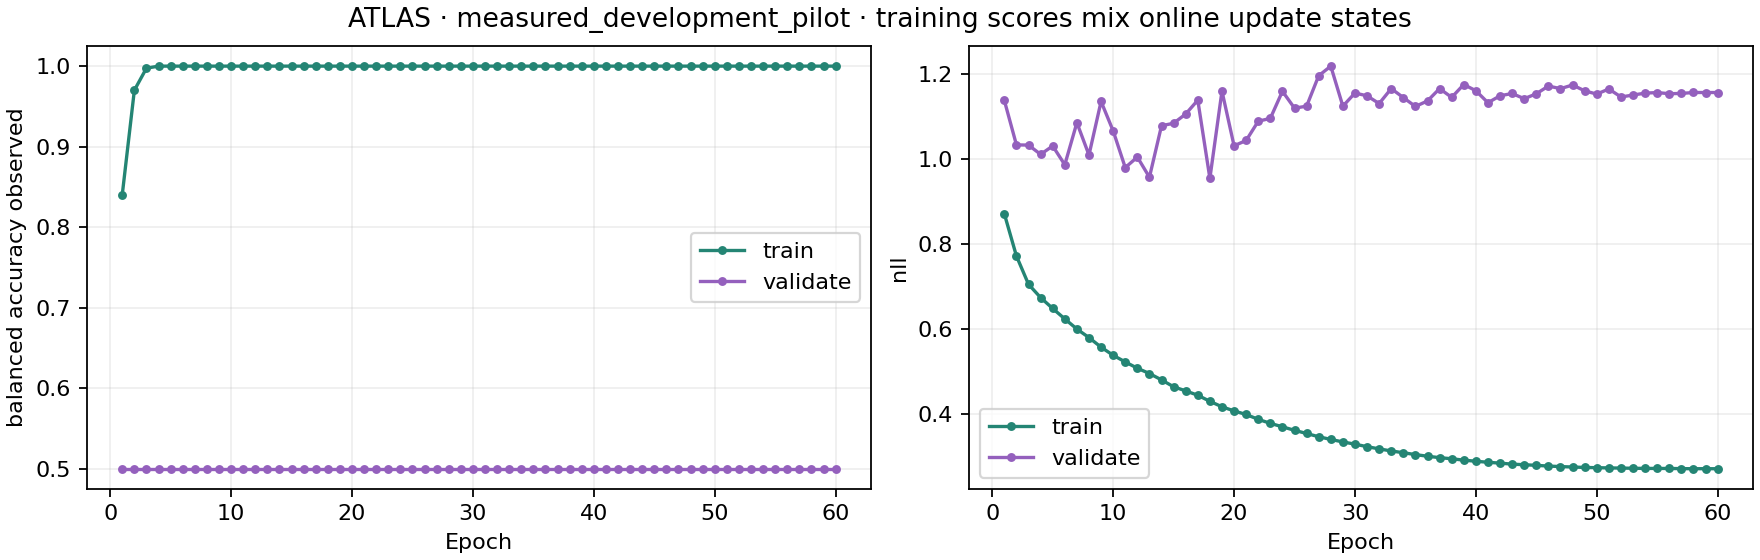

/kaggle/working/tread_two_atlas/snapshots/snapshot-1ddd8ba5de874492acce11c55d1acda8/report/ATLAS_Evidence_Explorer.html

/kaggle/working/tread_two_atlas/snapshots/snapshot-1ddd8ba5de874492acce11c55d1acda8/SCHEMA.json

Preserve this executed notebook. A completion audit must independently verify the pinned HF revision and scientific records.


In [6]:
import pandas as pd
from IPython.display import display, FileLink, Image
receipt = json.loads((WORK/'LAST_REMOTE.json').read_text())
latest = json.loads((WORK/'LATEST_SNAPSHOT.json').read_text())
SNAPSHOT = Path(latest['path'])
print(json.dumps(receipt, indent=2))
tables = [pd.read_csv(p) for p in sorted((SNAPSHOT/'csv').glob('epoch_*/metrics.csv'))]
metrics = pd.concat(tables, ignore_index=True)
display(metrics[(metrics['level']=='cohort') & metrics['stage'].isin(['selected_eval','final_eval'])])
display(Image(filename=str(SNAPSHOT/'report/training_curves.png')))
display(FileLink(str(SNAPSHOT/'report/ATLAS_Evidence_Explorer.html')))
display(FileLink(str(SNAPSHOT/'SCHEMA.json')))
print('Preserve this executed notebook. A completion audit must independently verify the pinned HF revision and scientific records.')


# Restart, storage and troubleshooting

| Situation | What to do |
|---|---|
| Normal restart / lost session | Enable the same input, T4×2 and secret, then Run All unchanged. Remote state is checked before resume/skip. |
| Catchable Stop | Wait for the flush result. The next run starts at the next completed update; an incomplete update is replayed. |
| Forced kernel/process death | Only the last verified remote snapshot is guaranteed recoverable; unsent local work may be lost. |
| Another active writer | The launcher waits up to 90 minutes for release/expiry. Do not delete ownership or open the same fit in two sessions. |
| Local HTTP budget / 429 | The repaired launcher waits for five-minute HTTP windows and actual server resets without converting a long quota wait to a fake network timeout. Commit attempts have a separate 96/hour guard. |
| Disk guard | Keep current files; flush/inspect space. Do not delete CSV/history or change the contract to force continuation. |
| Source/environment mismatch | Preserve files and this notebook; request a compatibility review. Do not delete the HF run or silently start it over. |
| Worker failure | Inspect `/kaggle/working/tread_two_atlas/run/console.log`, `NUMERICAL_EVENTS.jsonl`, `LIFECYCLE.jsonl` and `LAST_REMOTE.json`. |

HF layout: `phase3/tread-two/atlas-v1/engineering/<contract>` and
`phase3/tread-two/atlas-v1/fit/<contract>`. CSVs remain direct `.csv`; native
recovery/maps use `.pt`/`.npy`; manifests/source are direct JSON/Python. No ZIP,
NPZ or database is uploaded. Historical study/model/workstation files are untouched.

The 18 cases come from only 1/3/4 original training tyres. Paint, glare,
identity and view shortcuts remain possible. Exact evidence accounting is
not causal reasoning, calibration or proof of physical wear measurement.
